In [ ]:
import tensorflow as tf
from tensorflow import keras
import os
import numpy as np
import matplotlib.pyplot as plt
seed=0
np.random.seed(seed) # fix random seed
tf.random.set_seed(seed)

EXERCISE 12.1

In [ ]:
from keras.datasets import mnist

# input image dimensions
img_rows, img_cols = 28, 28 # number of pixels
# output
num_classes = 10 # 10 digits

# the data, split between train and test sets
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

X_train shape: (60000, 28, 28)
Y_train shape: (60000,)


In [ ]:
# Consider an array of 5 labels out of a set of 3 classes {0, 1, 2}:
labels = np.array([0, 2, 1, 2, 0])
# `to_categorical` converts this into a matrix with as many columns as there are classes.
# The number of rows stays the same.
keras.utils.to_categorical(labels)

array([[1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

X_train shape: (60000, 784)
X_test shape: (10000, 784)

an example of a data point with label 4


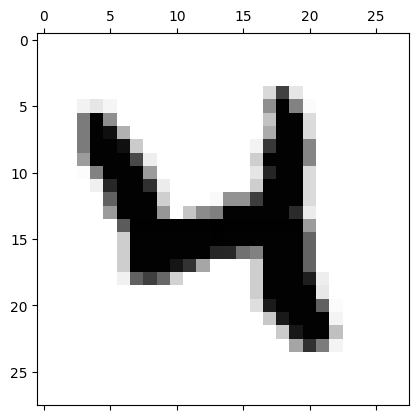

... and with label [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.] after to_categorical

X_train shape: (60000, 784)
Y_train shape: (60000, 10)


In [ ]:
# reshape data, it could depend on Keras backend
X_train = X_train.reshape(X_train.shape[0], img_rows*img_cols)
X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print()

# cast to floats
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# rescale data in interval [0,1]
X_train /= 255.0
X_test /= 255.0
# normalizzo sempre i dati prima di inserirli

# look at an example of data point
print('an example of a data point with label', Y_train[20])
# matshow: display a matrix in a new figure window
plt.matshow(X_train[20,:].reshape(28,28),cmap='binary')
plt.show()

# convert class vectors to binary class matrices, e.g. for use with categorical_crossentropy
Y_train = keras.utils.to_categorical(Y_train, num_classes)
Y_test = keras.utils.to_categorical(Y_test, num_classes)
print('... and with label', Y_train[20], 'after to_categorical')
print()
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)


In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Dropout

def create_DNN():
    # instantiate model
    model = Sequential()
    # add a dense all-to-all relu layer
    model.add(Dense(400,input_shape=(img_rows*img_cols,), activation='relu'))
    # add a dense all-to-all relu layer
    model.add(Dense(100, activation='relu'))
    # apply dropout with rate 0.5
    model.add(Dropout(0.5))
    # soft-max layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

print('Model architecture created successfully!')

Model architecture created successfully!


In [ ]:
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adamax, Nadam

def compile_model(optimizer=SGD()):
    # create the model
    model=create_DNN()
    # compile the model with the specified optimizer
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=optimizer,
                  metrics=['acc'])
    return model

print('Model compiled successfully and is now flexible to use any optimizer.')

Model compiled successfully and is now flexible to use any optimizer.


In [ ]:
# training parameters
batch_size = 64
epochs = 15
optimizer_list = [('SGD', SGD()), ('Adam', Adam()), ('RMSprop', RMSprop()), ('Adamax', Adamax())]

# Ensure data is flattened to 784 features for the DNN before training
X_train = X_train.reshape(X_train.shape[0], img_rows * img_cols)
X_test = X_test.reshape(X_test.shape[0], img_rows * img_cols)

histories = {}
scores = {}

for name, opt in optimizer_list:
    print(f"\n--- Training in corso con l'ottimizzatore: {name} ---")

    # create a fresh model for each optimizer to ensure a clean start
    model_DNN = compile_model(optimizer=opt)

    # train the model
    history = model_DNN.fit(X_train, Y_train,
                            batch_size=batch_size,
                            epochs=epochs,
                            shuffle=True,
                            verbose=1,
                            validation_data=(X_test, Y_test))

    histories[name] = history
    scores[name] = model_DNN.evaluate(X_test, Y_test, verbose=0)


--- Training in corso con l'ottimizzatore: SGD ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - acc: 0.6874 - loss: 1.0540 - val_acc: 0.8936 - val_loss: 0.4304
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - acc: 0.8528 - loss: 0.5146 - val_acc: 0.9150 - val_loss: 0.3165
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - acc: 0.8837 - loss: 0.4139 - val_acc: 0.9249 - val_loss: 0.2713
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - acc: 0.8973 - loss: 0.3641 - val_acc: 0.9317 - val_loss: 0.2422
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - acc: 0.9089 - loss: 0.3285 - val_acc: 0.9371 - val_loss: 0.2181
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - acc: 0.9156 - loss: 0.2983 - val_acc: 0.9413 - val_loss: 0.2030
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - acc: 0.9229 - loss: 0.2772 - val_acc: 0.9454 - val_loss: 0.1888
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - acc: 0.9276 - loss: 0.2576 - val_acc: 0.9482 - val_loss: 0.1755
Epoch 9/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - a


=== Training History Analysis for Optimizer: SGD ===


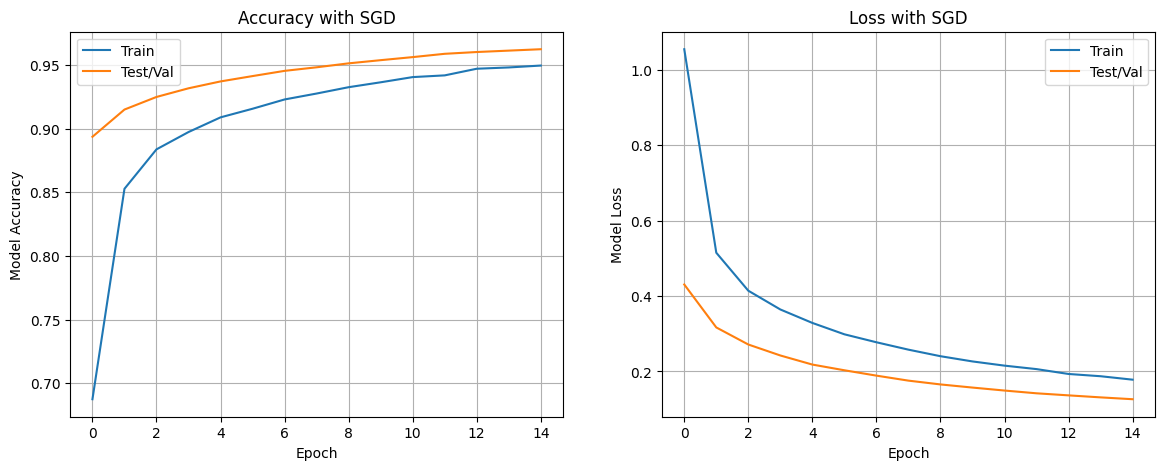


=== Training History Analysis for Optimizer: Adam ===


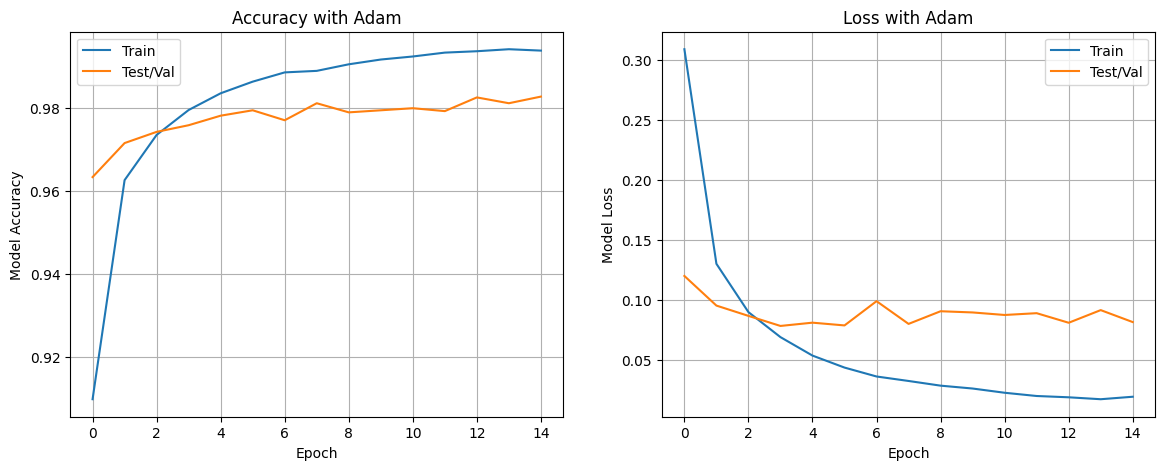


=== Training History Analysis for Optimizer: RMSprop ===


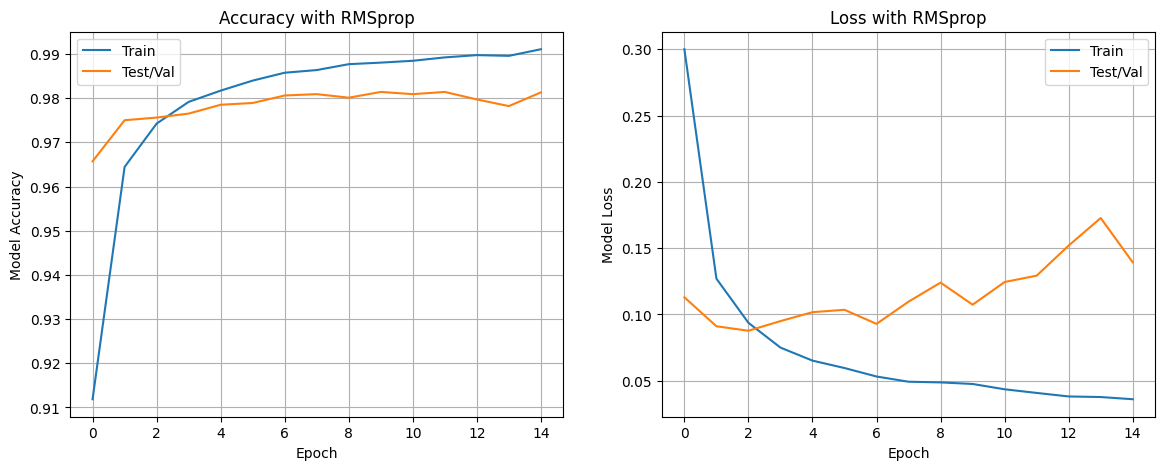


=== Training History Analysis for Optimizer: Adamax ===


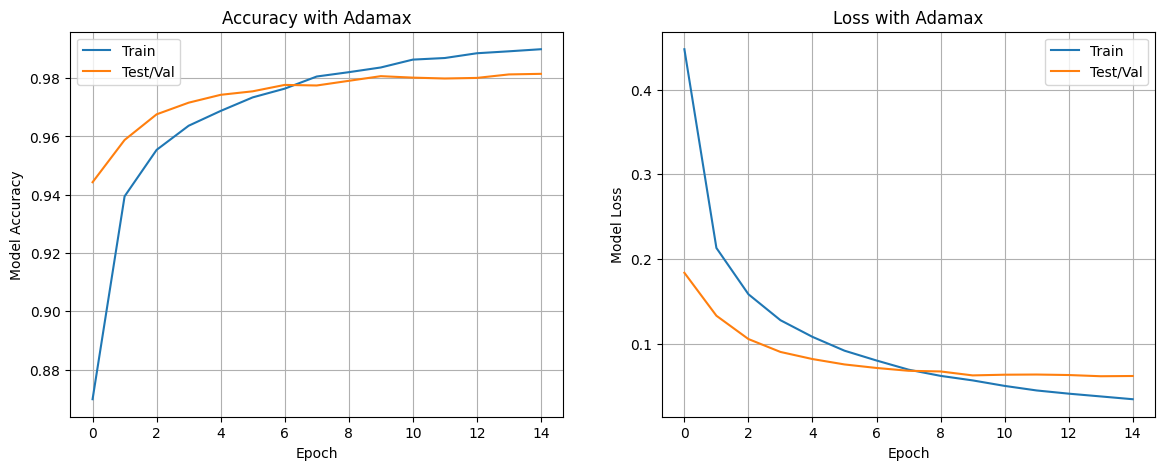

In [ ]:
# --- Visualizing Training vs Validation Performance for each Optimizer ---
# Reshape to flat format for evaluation if needed
X_test_flat = X_test.reshape(X_test.shape[0], img_rows * img_cols)

for name, _ in optimizer_list:
    print(f"\n=== Training History Analysis for Optimizer: {name} ===")
    history = histories[name]

    plt.figure(figsize=(14, 5))

    # 1. Accuracy Curves (Train vs Test)
    plt.subplot(1, 2, 1)
    plt.plot(history.history['acc'], label='Train')
    plt.plot(history.history['val_acc'], label='Test/Val')
    plt.ylabel('Model Accuracy')
    plt.xlabel('Epoch')
    plt.title(f'Accuracy with {name}')
    plt.legend(loc='best')
    plt.grid(True)

    # 2. Loss Curves (Train vs Test)
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Test/Val')
    plt.ylabel('Model Loss')
    plt.xlabel('Epoch')
    plt.title(f'Loss with {name}')
    plt.legend(loc='best')
    plt.grid(True)

    plt.show()

In [ ]:
# --- Final Results ---
print("\n--- Final Results ---")
for name, _ in optimizer_list:
    print(f"Optimizer: {name} -> Test Loss: {scores[name][0]:.4f}, Test Accuracy: {scores[name][1]:.4f}")


--- Final Results ---
Optimizer: SGD -> Test Loss: 0.1262, Test Accuracy: 0.9624
Optimizer: Adam -> Test Loss: 0.0819, Test Accuracy: 0.9828
Optimizer: RMSprop -> Test Loss: 0.1393, Test Accuracy: 0.9813
Optimizer: Adamax -> Test Loss: 0.0622, Test Accuracy: 0.9815


EXERCISE 12.2


In [ ]:
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Input shape for CNN
input_shape = (img_rows, img_cols, 1)

def create_CNN():
    # instantiate model
    model = Sequential()
    # add first convolutional layer with 10 filters
    model.add(Conv2D(10, kernel_size=(5, 5),
                     activation='relu',
                     input_shape=input_shape))
    # MaxPooling
    model.add(MaxPooling2D(pool_size=(2, 2)))
    # Conv2D with 20 filters
    model.add(Conv2D(20, kernel_size=(5, 5), activation='relu'))
    # MaxPooling
    model.add(MaxPooling2D(pool_size=(2, 2)))
    # Dropout
    model.add(Dropout(0.25))
    # Flatten to transition to fully connected layers
    model.add(Flatten())
    # Dense with 128 neurons
    model.add(Dense(128, activation='relu'))
    # Dropout
    model.add(Dropout(0.5))
    # Softmax output layer with 10 classes
    model.add(Dense(num_classes, activation='softmax'))

    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer='Adam',
                  metrics=['acc'])
    return model

print('CNN Architecture defined and compiled successfully!')

CNN Architecture defined and compiled successfully!


In [ ]:
# training parameters
batch_size = 64
epochs = 15

# Reshape data to 4D (batch, height, width, channels) for CNN compatibility
X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)

print('X_train shape for CNN:', X_train.shape)
print('X_test shape for CNN:', X_test.shape)

# create the deep conv net
model_CNN = create_CNN()

# train CNN
history_CNN = model_CNN.fit(X_train, Y_train,
                            batch_size=batch_size,
                            epochs=epochs,
                            verbose=1,
                            validation_data=(X_test, Y_test))

# evaluate model
score = model_CNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

X_train shape for CNN: (60000, 28, 28, 1)
X_test shape for CNN: (10000, 28, 28, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 36s 35ms/step - acc: 0.8814 - loss: 0.3739 - val_acc: 0.9776 - val_loss: 0.0735
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - acc: 0.9595 - loss: 0.1342 - val_acc: 0.9845 - val_loss: 0.0478
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 31ms/step - acc: 0.9692 - loss: 0.1025 - val_acc: 0.9876 - val_loss: 0.0383
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 33ms/step - acc: 0.9754 - loss: 0.0827 - val_acc: 0.9889 - val_loss: 0.0342
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - acc: 0.9780 - loss: 0.0724 - val_acc: 0.9885 - val_loss: 0.0363
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - acc: 0.9804 - loss: 0.0648 - val_acc: 0.9910 - val_loss: 0.0289
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 31ms/step - acc: 0.9822 - loss: 0.0583 - val_acc: 0.9912 - val_loss: 0.0293
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 31ms/step - acc: 0.9833 - loss: 0.0558 - val_acc: 0.9914 - val_loss: 0.0263
Epoch 9/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Input shape for CNN
input_shape = (img_rows, img_cols, 1)

def create_CNN():
    # instantiate model
    model = Sequential()
    # add first convolutional layer with 10 filters
    model.add(Conv2D(10, kernel_size=(5, 5),
                     activation='relu',
                     input_shape=input_shape))
    # MaxPooling
    model.add(MaxPooling2D(pool_size=(2, 2)))
    # Conv2D with 20 filters
    model.add(Conv2D(20, kernel_size=(5, 5), activation='relu'))
    # MaxPooling
    model.add(MaxPooling2D(pool_size=(2, 2)))
    # Dropout
    model.add(Dropout(0.25))
    # Flatten to transition to fully connected layers
    model.add(Flatten())
    # Dense with 128 neurons
    model.add(Dense(128, activation='relu'))
    # Dropout
    model.add(Dropout(0.5))
    # Softmax output layer with 10 classes
    model.add(Dense(num_classes, activation='softmax'))

    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer='RMSprop',
                  metrics=['acc'])
    return model

print('CNN Architecture defined and compiled successfully!')

CNN Architecture defined and compiled successfully!


In [ ]:
# training parameters
batch_size = 64
epochs = 15

# Reshape data to 4D (batch, height, width, channels) for CNN compatibility
X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)

print('X_train shape for CNN:', X_train.shape)
print('X_test shape for CNN:', X_test.shape)

# create the deep conv net
model_CNN = create_CNN()

# train CNN
history_CNN = model_CNN.fit(X_train, Y_train,
                            batch_size=batch_size,
                            epochs=epochs,
                            verbose=1,
                            validation_data=(X_test, Y_test))

# evaluate model
score = model_CNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

X_train shape for CNN: (60000, 28, 28, 1)
X_test shape for CNN: (10000, 28, 28, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 33s 34ms/step - acc: 0.8886 - loss: 0.3558 - val_acc: 0.9784 - val_loss: 0.0709
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - acc: 0.9614 - loss: 0.1269 - val_acc: 0.9858 - val_loss: 0.0421
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 31ms/step - acc: 0.9712 - loss: 0.0960 - val_acc: 0.9881 - val_loss: 0.0380
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - acc: 0.9762 - loss: 0.0809 - val_acc: 0.9889 - val_loss: 0.0313
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 31ms/step - acc: 0.9784 - loss: 0.0718 - val_acc: 0.9899 - val_loss: 0.0286
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - acc: 0.9815 - loss: 0.0618 - val_acc: 0.9908 - val_loss: 0.0262
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 34ms/step - acc: 0.9821 - loss: 0.0588 - val_acc: 0.9910 - val_loss: 0.0254
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - acc: 0.9834 - loss: 0.0536 - val_acc: 0.9928 - val_loss: 0.0224
Epoch 9/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 

EXERCISE 12.3

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


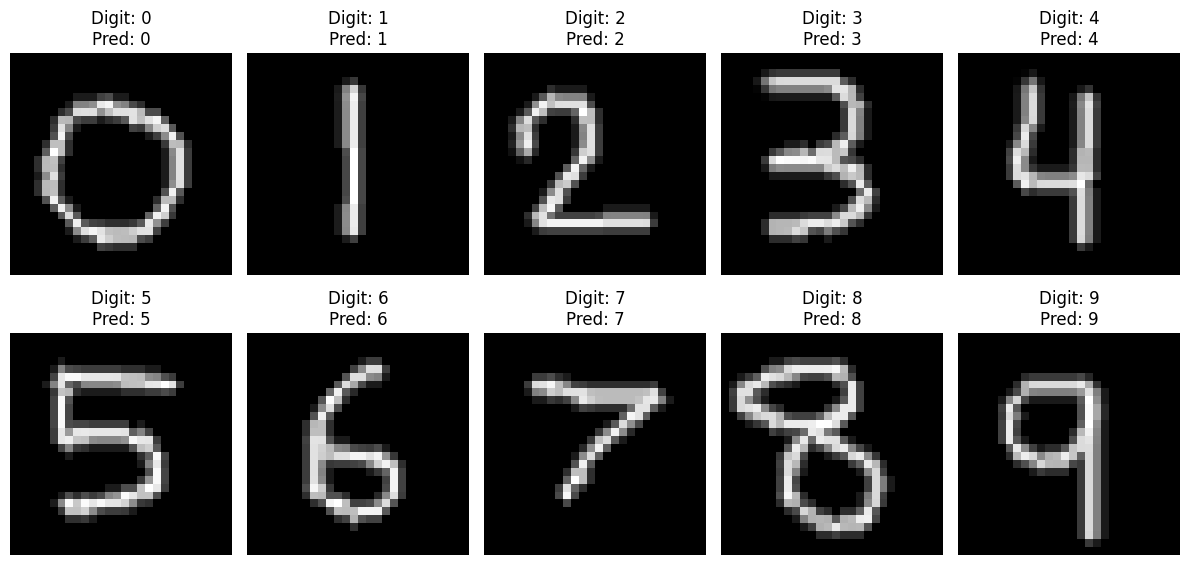

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def predict_digit(filename):
    # Load and process the image to 28x28 grayscale
    img = Image.open(filename).convert('L').resize((28, 28))
    data = np.array(img)
    # Check if background is white and invert to match MNIST (white digits on black background)
    if np.mean(data) > 127:
        data = 255.0 - data
    data = data / 255.0
    data = data.reshape(1, 28, 28, 1).astype(np.float32)
    pred = model_CNN.predict(data)
    pred_digit = np.argmax(pred)
    return img, pred_digit

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(10):
    # Load your custom digits: digit0.png through digit9.png
    filename = f"digit{i}.png"
    try:
        img, pred = predict_digit(filename)
        r = i // 5
        c = i % 5
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].set_title(f"Digit: {i}\nPred: {pred}")
        axes[r, c].axis('off')
    except FileNotFoundError:
        r = i // 5
        c = i % 5
        axes[r, c].text(0.5, 0.5, f"Missing\n{filename}", ha='center', va='center')
        axes[r, c].axis('off')

plt.tight_layout()
plt.show()